In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import itertools



## Importación de fuente de datos


In [2]:
#Lectura datos históricos
df = pd.read_csv('../data/raw/vectoria_acciones.csv',encoding = "ISO-8859-1",delimiter=',')

In [3]:

# Definición de variables predictoras (X) y objetivo (y)
# Filtramos las columnas que realmente aportan al modelo 
columnas_X = [
    'casos_pred_4sem', 
    'casos_umbral_endemico', 
    'lluvia_14d_mm', 
    'temp_max', 
    'temp_min', 
    'humedad', 
    'aegypti_detectado'
]

X = df[columnas_X]
y = df['recomendacion'] 


## MODELADO

In [4]:
# Transformación de la variable categórica objetivo a formato Dummy (One-Hot Encoding)

y_dummies = pd.get_dummies(y)
y_values = y_dummies.values


In [5]:

# Train/Test Split agrupado por semana para evitar fuga de datos
# Usamos fecha_inicio como nuestro grupo 
grupos = df['fecha_inicio_semana'] 


In [6]:

# se divide el dataset en train y test usando GroupShuffleSplit para evitar fuga de datos
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=101)


In [7]:

# Obtenemos los índices de las filas para train y test
train_idx, test_idx = next(gss.split(X, y_values, groups=grupos))

# Separamos los datos usando los índices
X_train = X.iloc[train_idx].values
X_test = X.iloc[test_idx].values
y_train = y_values[train_idx]
y_test = y_values[test_idx]


In [8]:

# Comprobación de dimensiones
print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")


Dimensiones de X_train: (1545, 7)
Dimensiones de X_test: (515, 7)


In [9]:

# Escalado de datos
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)


In [10]:
y_train_labels = np.argmax(y_train, axis=1)
pesos_originales = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_labels),
    y=y_train_labels
)

# TRUCO: Forzamos a que el peso mínimo sea 1.0 para que no ignore la clase mayoritaria
pesos_suavizados = {i: max(1.0, peso) for i, peso in enumerate(pesos_originales)}
print("Pesos suavizados (mínimo 1.0):", pesos_suavizados)


Pesos suavizados (mínimo 1.0): {0: np.float64(1.3048986486486487), 1: np.float64(1.5895061728395061), 2: np.float64(3.981958762886598), 3: 1.0}


In [11]:

# Se crea el modelo ANN
model = Sequential()


In [12]:

# Entradas y salidas
num_neuronas_entrada = X_train.shape[1] 
num_neuronas_salida = y_train.shape[1] 

# Capa oculta 1
model.add(Dense(units=16, activation='relu', input_shape=(num_neuronas_entrada,)))

# Capa oculta 2 
model.add(Dropout(0.2)) 
model.add(Dense(units=8, activation='relu'))
model.add(Dense(units=num_neuronas_salida, activation='softmax'))





/Users/brandonacunagamboa/Documents/GitHub/Proyecto_2_VectorIA/venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:

# Compilación del modelo

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'categorical_accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)


In [14]:

# Entrenamiento del modelo
# Usamos EarlyStopping para evitar un sobreentrenamiento
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=15)

# Entrenamiento del modelo con los pesos suavizados para balancear las clases
print("Entrenando red neuronal (Pesos Suavizados + Dropout)")
history = model.fit(
    x=X_train,
    y=y_train,
    epochs=150, 
    batch_size=32, 
    validation_data=(X_test, y_test),
    verbose=1,
    callbacks=[early_stop],
    class_weight=pesos_suavizados # Usamos los pesos corregidos
)


Entrenando red neuronal (Pesos Suavizados + Dropout)
Epoch 1/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - categorical_accuracy: 0.4472 - loss: 1.8430 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_categorical_accuracy: 0.5903 - val_loss: 1.3070 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - categorical_accuracy: 0.5883 - loss: 1.7916 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_categorical_accuracy: 0.5903 - val_loss: 1.2587 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 692us/step - categorical_accuracy: 0.5883 - loss: 1.7528 - precision: 0.4000 - recall: 0.0013 - val_categorical_accuracy: 0.5903 - val_loss: 1.2158 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/150
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step - categorical_accuracy: 0.5883 - loss: 1.7109 - precision: 0.2143 - recall: 0.0019 - val_categorical_accuracy: 0.5903 - val_loss: 1.1649 - val_precisio

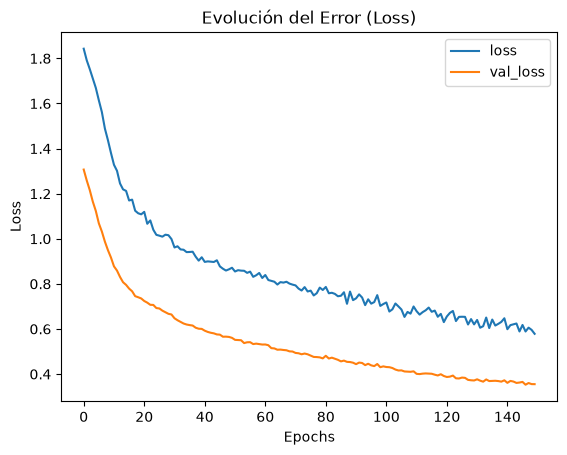

In [15]:
loss_df = pd.DataFrame(history.history)
loss_df[['loss', 'val_loss']].plot(title='Evolución del Error (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()


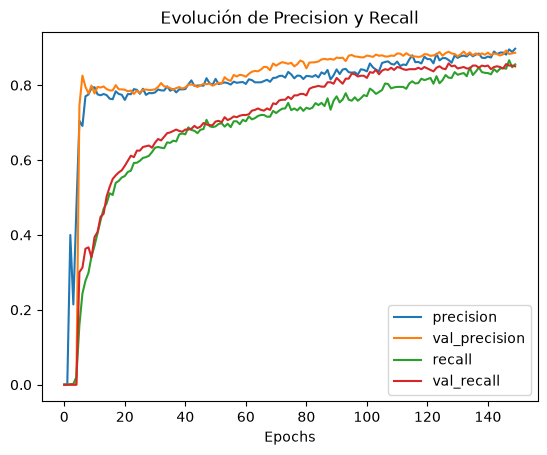

In [16]:

# Y graficamos las métricas clave para la nota:
loss_df[['precision', 'val_precision', 'recall', 'val_recall']].plot(title='Evolución de Precision y Recall')
plt.xlabel('Epochs')
plt.show()


## Test

In [17]:
# Obtener las predicciones del modelo sobre el set de prueba (Test)
predictions = model.predict(X_test)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [18]:

# Convertimos las predicciones y los valores reales de One-Hot (matrices de 0s y 1s) 
# de vuelta a índices (0, 1, 2, 3) para poder compararlos
predictions_lab = np.argmax(predictions, axis=-1)
y_test_lab = np.argmax(y_test, axis=-1)


In [19]:

# Obtenemos los nombres de las clases directamente de los dummies que creamos antes
# Serían: 'alerta_sanitaria', 'eliminacion_criaderos', 'fumigacion_focalizada', 'monitoreo_normal'
nombres_clases = y_dummies.columns.tolist()


In [20]:
# Reporte de Clasificación 
print("--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test_lab, predictions_lab, target_names=nombres_clases))


--- REPORTE DE CLASIFICACIÓN ---
                       precision    recall  f1-score   support

     alerta_sanitaria       0.96      0.83      0.89        83
eliminacion_criaderos       0.80      0.77      0.78        78
fumigacion_focalizada       0.68      0.92      0.78        50
     monitoreo_normal       0.91      0.90      0.90       304

             accuracy                           0.87       515
            macro avg       0.84      0.85      0.84       515
         weighted avg       0.88      0.87      0.87       515



In [21]:

# Matriz de Confusión (Adaptada del código del profe)
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Matriz de Confusión',
                          cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    # Le puse ha='right' para que el texto largo de las clases no se monte
    plt.xticks(tick_marks, classes, rotation=45, ha='right') 
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('Etiqueta Real')
    plt.xlabel('Etiqueta Predicha')
    plt.tight_layout()


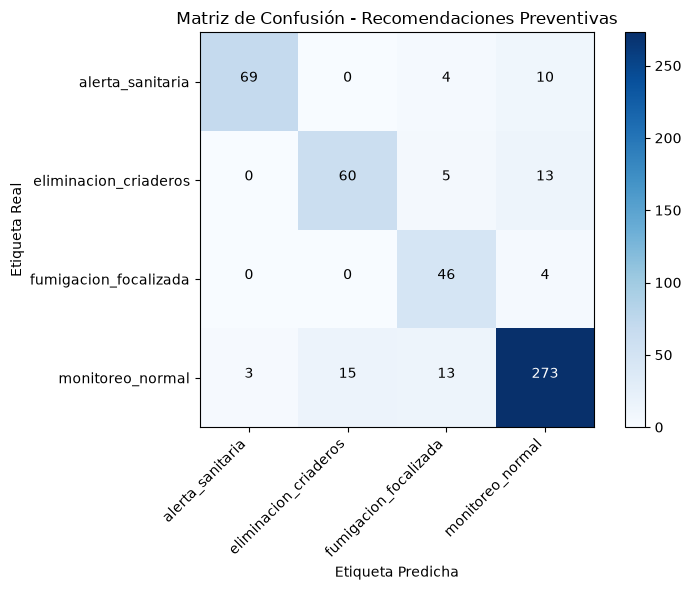

In [22]:

# Generamos y graficamos la matriz
cnf_matrix = confusion_matrix(y_test_lab, predictions_lab)
plt.figure(figsize=(8, 6))
plot_confusion_matrix(cnf_matrix, classes=nombres_clases, title='Matriz de Confusión - Recomendaciones Preventivas')
plt.show()


In [23]:
import joblib
joblib.dump(scaler, 'models/scaler_ann.pkl')
print("¡Escalador guardado exitosamente como 'models/scaler_ann.pkl'!")


FileNotFoundError: [Errno 2] No such file or directory: 'models/scaler_ann.pkl'

In [ ]:

# 4. Guardar el modelo entrenado

import os
os.makedirs('models', exist_ok=True) # Crea la carpeta si no existe
model.save('models/ann.h5')
print("¡Modelo guardado exitosamente como 'models/ann.h5'!")
